In [1]:
import pandas as pd
import numpy as np

sample_meta = pd.read_csv('./metadata_files/master_sample_metadata_111226.csv')
peps_meta = pd.read_csv('./metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')
peps_metadata = peps_meta.set_index('seq_id')


df= pd.read_csv('./output_files/long_spec_0_98_111226.csv')


In [2]:
df.groupby('category')['individual'].nunique()

category
Household contact    277
Lassa survivor       120
US healthy            87
Name: individual, dtype: int64

In [3]:
#subset to first timepoint

sample_meta_baseline = sample_meta.loc[sample_meta['sample_id'].isin(df['individual'].to_list())]

## First analysis is to do a simple peptide-by-peptide analysis: 

### ELISA seropositive ~ peptide reactivity 

In [4]:
print(sample_meta_baseline.shape)
print(sample_meta_baseline.columns.to_list())

print(df.shape)
print(df.columns.to_list())

display(sample_meta_baseline.head(2))
display(df.head(2))

(397, 49)
['sample_id', 'participant_id', 'lassa_ID', 'lassa_Enrolled_Type', 'Category', 'collection_date', 'collection_year', 'collection_month', 'collection_year_month', 'baseline_date', 'visit_number', 'days_since_baseline', 'years_since_baseline', 'days_since_previous_visit', 'discharge_date', 'years_since_discharge', 'days_since_discharge', 'NP_Calc_Conc', 'NP_FINAL_RESULT', 'GP_Calc_Conc', 'GP_FINAL_RESULT', 'Serology_Result_Corrected', 'Serology_Positive', 'ELISA_complete', 'Neut_Percent', 'Neut_Result', 'sex', 'age_years', 'district', 'chiefdom', 'village', 'demo_occupation', 'demo_marital_status', 'inventory_location', 'inventory_box_aliquot', 'inventory_name', 'HL.L.SEV', 'HL.R.SEV', 'type', 'DIFF.STATUS', 'hearing_present', 'lassa_District', 'lassa_Chiefdom', 'lassa_VillageTown', 'missing_sex', 'missing_age_years', 'missing_district', 'missing_chiefdom', 'missing_village']
(2266572, 13)
['peptide', 'individual', 'z_score', 'rpk', 'sequence', 'species', 'genus', 'family', 'pr

,sample_id,participant_id,lassa_ID,lassa_Enrolled_Type,Category,collection_date,collection_year,collection_month,collection_year_month,baseline_date,...,DIFF.STATUS,hearing_present,lassa_District,lassa_Chiefdom,lassa_VillageTown,missing_sex,missing_age_years,missing_district,missing_chiefdom,missing_village
0,C-109-1_5_B3,C-109-1,109-1,Contact to 109,C,12/1/20,2020,12,2020-12,12/1/20,...,NaN,NaN,Kenema,Lower Bambara,Panguma,NaN,NaN,NaN,NaN,NaN
1,C-109-2_5_B5,C-109-2,109-2,Contact to 109,C,12/2/20,2020,12,2020-12,12/2/20,...,NaN,NaN,Kenema,Lower Bambara,Panguma,NaN,NaN,NaN,NaN,NaN


,peptide,individual,z_score,rpk,sequence,species,genus,family,protein_std,accession,cohort,category,reactive
0,AAA16239.1|polypeptide|Orthohantavirus_thailan...,C-109-3_4_E7,-0.981090,0.180069,LPITEAEQLVPESSCNMDNHQSLATINTLTKVSWRKKADQVSASQN,Orthohantavirus thailandense,Orthohantavirus,Hantaviridae,glycoprotein,AAA16239.1,SL,Household contact,False
1,AAA16239.1|polypeptide|Orthohantavirus_thailan...,C-109-3_4_E7,-0.607326,0.263884,SFQSFNTSSIHFTDERLMEDPDGMLRDHINIVVTKDIDFENLAENL,Orthohantavirus thailandense,Orthohantavirus,Hantaviridae,glycoprotein,AAA16239.1,SL,Household contact,False


In [5]:
#correct the seropositive boolean column (double check)

sample_meta_baseline['seropositive'] = ((sample_meta_baseline['NP_FINAL_RESULT'] == 'Positive') & (sample_meta_baseline['GP_FINAL_RESULT'] == 'Positive'))

/tmp/ipykernel_2335173/909034388.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample_meta_baseline['seropositive'] = ((sample_meta_baseline['NP_FINAL_RESULT'] == 'Positive') & (sample_meta_baseline['GP_FINAL_RESULT'] == 'Positive'))


In [6]:
# add serostatus directly to the long dataset

df = df.merge(sample_meta_baseline[['sample_id', 'participant_id', 'seropositive', 
                           'NP_FINAL_RESULT', 'GP_FINAL_RESULT']], 
                           left_on='individual', right_on='sample_id', how='left')

In [7]:
# restrict to Lassa peptides

df_lassa_cohort = df.loc[(df['species'] == 'Mammarenavirus lassaense') & (df['cohort'] == 'SL')]

In [8]:
df_wide_lassa = df_lassa_cohort.pivot_table(columns='peptide', index='individual', values='reactive')

In [9]:
# add serostatus

serostatus = (sample_meta_baseline.drop_duplicates('participant_id')
              .set_index('sample_id')['seropositive']) #index is participant_id, value is seropositive

df_wide_lassa['ELISA_seropositive'] = (df_wide_lassa.index.map(serostatus))

In [10]:
df_wide_lassa['ELISA_seropositive'].value_counts()

ELISA_seropositive
True     204
False    193
Name: count, dtype: int64

In [11]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

#outcome

y = df_wide_lassa['ELISA_seropositive'].astype(bool)

#peptide features

X = df_wide_lassa.drop(columns='ELISA_seropositive').astype(bool)

results = []

for peptide in X.columns:

    pep = X[peptide]

    # 2 x 2 table
    tp = ((pep == True) & (y == True)).sum()
    fp = ((pep == True) & (y == False)).sum()
    fn = ((pep == False) & (y == True)).sum()
    tn = ((pep == False) & (y == False)).sum()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    # difference in prevalence: 
    # peptide prevalence in ELISA+ minus peptide prevalence in ELISA - 

    delta_prevalence = sensitivity - ( 1 - specificity )

    odds_ratio, p_value = fisher_exact(
        [[tp, fp], 
        [fn, tn]],
        alternative = 'two-sided'
    )

    results.append({
        'peptide': peptide, 
        'TP': tp, 
        'FP': fp, 
        'FN': fn, 
        'TN': tn, 
        'sensitivity': sensitivity, 
        'specificity': specificity, 
        'delta_prevalence': delta_prevalence, 
        'odds_ratio': odds_ratio, 
        'p_value': p_value
    })

peptide_results = pd.DataFrame(results)

# multiple testing correction
peptide_results['FDR'] = multipletests(
    peptide_results['p_value'], method='fdr_bh'
)[1]

#rank primarily by separation between ELISA + and ELISA - 
peptide_results = peptide_results.sort_values('delta_prevalence', ascending=False)

peptide_results.head(20)

,peptide,TP,FP,FN,TN,sensitivity,specificity,delta_prevalence,odds_ratio,p_value,FDR
231,WKK95338.1|nucleoprotein|Mammarenavirus_lassae...,98,48,106,145,0.480392,0.751295,0.231687,2.792846,1.636847e-06,0.000199
233,WNI01985.1|nucleoprotein|Mammarenavirus_lassae...,96,47,108,146,0.470588,0.756477,0.227065,2.761229,2.429890e-06,0.000199
156,AZI96445.1|nucleoprotein|Mammarenavirus_lassae...,79,31,125,162,0.387255,0.839378,0.226633,3.302710,3.895066e-07,0.000096
152,AZI96407.1|nucleoprotein|Mammarenavirus_lassae...,100,51,104,142,0.490196,0.735751,0.225947,2.677225,4.782788e-06,0.000294
189,UCR17179.1|nucleoprotein|Mammarenavirus_lassae...,73,33,131,160,0.357843,0.829016,0.186859,2.701827,2.547012e-05,0.000895
33,ANH09737.1|nucleoprotein|Mammarenavirus_lassae...,59,21,145,172,0.289216,0.891192,0.180407,3.332677,9.069254e-06,0.000446
204,UKY81278.1|nucleoprotein|Mammarenavirus_lassae...,63,25,141,168,0.308824,0.870466,0.179290,3.002553,1.945332e-05,0.000798
34,ANH09740.1|precursor|Mammarenavirus_lassaense|...,59,23,145,170,0.289216,0.880829,0.170045,3.007496,3.531523e-05,0.001086
131,AZI95980.1|nucleoprotein|Mammarenavirus_lassae...,66,31,138,162,0.323529,0.839378,0.162908,2.499299,1.739351e-04,0.003757
240,XBA96065.1|precursor|Mammarenavirus_lassaense|...,68,36,136,157,0.333333,0.813472,0.146805,2.180556,9.288489e-04,0.012694


In [12]:
# annotate peptides

annotation_cols = ['protein_std', 'sequence', 'species', 'accession']

peptide_results = peptide_results.merge(
    peps_metadata[annotation_cols], left_on='peptide', right_index=True, how='left'
)

In [13]:
peptide_results.loc[peptide_results['FDR'] < 0.05].head(3)

,peptide,TP,FP,FN,TN,sensitivity,specificity,delta_prevalence,odds_ratio,p_value,FDR,protein_std,sequence,species,accession
231,WKK95338.1|nucleoprotein|Mammarenavirus_lassae...,98,48,106,145,0.480392,0.751295,0.231687,2.792846,1.636847e-06,0.000199,nucleoprotein,KAGSNGSNKSLQSAGFTAGLTYSQLMTLKDAMLQLDPNAKTWMDIE,Mammarenavirus lassaense,WKK95338.1
233,WNI01985.1|nucleoprotein|Mammarenavirus_lassae...,96,47,108,146,0.470588,0.756477,0.227065,2.761229,2.429890e-06,0.000199,nucleoprotein,KVGTAGSNKSLQSAGFPTGLTYSQLMTLKDSMMQLDPSAKTWIDIE,Mammarenavirus lassaense,WNI01985.1
156,AZI96445.1|nucleoprotein|Mammarenavirus_lassae...,79,31,125,162,0.387255,0.839378,0.226633,3.302710,3.895066e-07,0.000096,nucleoprotein,KPGNNGSNRSLQSAGFPAGLTYSQLMTLKDSMLQLDPNAKTWMDIE,Mammarenavirus lassaense,AZI96445.1


In [14]:
peptide_results['ELISA_pos_prevalence'] = peptide_results['sensitivity']
peptide_results['ELISA_neg_prevalence'] = 1 - peptide_results['specificity']

Text(0.5, 1.0, 'Which peptides correspond best to dual GP & NP ELISA seropositivity?')

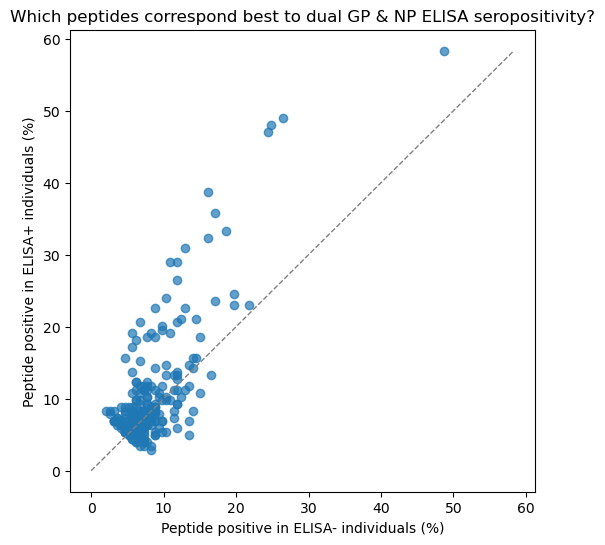

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    peptide_results['ELISA_neg_prevalence'] * 100, 
    peptide_results['ELISA_pos_prevalence'] * 100, 
    alpha=0.7
)

#y = x reference
lim = max(
    peptide_results['ELISA_neg_prevalence'].max(), 
    peptide_results['ELISA_pos_prevalence'].max()
) * 100 

ax.plot([0, lim], [0, lim], '--', color='grey', linewidth=1)

ax.set_xlabel('Peptide positive in ELISA- individuals (%)')
ax.set_ylabel('Peptide positive in ELISA+ individuals (%)')

ax.set_title('Which peptides correspond best to dual GP & NP ELISA seropositivity?')

## Changing analysis to compare Survivor peptide reactivities to contacts which exhibit dual negative ELISA-derived serostatus. so reactive to neither glycoprotein, nor nucleoprotein. Then see which peptides are the ones which best distinguish survivors from this group. 

In [16]:
analysis_meta = sample_meta_baseline[
    (sample_meta_baseline['Category'] == 'S') |
    (
        (sample_meta_baseline['Category'] == 'C') &
        (sample_meta_baseline['NP_FINAL_RESULT'] == 'Negative') &
        (sample_meta_baseline['GP_FINAL_RESULT'] == 'Negative')
    )
].copy()

analysis_meta['LASV_exposure_group'] = (
    analysis_meta['Category'] == 'S'
)

analysis_meta['LASV_exposure_group'].value_counts()

LASV_exposure_group
True     120
False     39
Name: count, dtype: int64

In [18]:
exposure_status = (
    analysis_meta
    .set_index('sample_id')['LASV_exposure_group']
)

df_exposure = df_wide_lassa.loc[
    df_wide_lassa.index.isin(exposure_status.index)
].copy()

df_exposure['LASV_exposure_group'] = (
    df_exposure.index.map(exposure_status)
)

df_exposure['LASV_exposure_group'].value_counts()

LASV_exposure_group
True     120
False     39
Name: count, dtype: int64

In [ ]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
import pandas as pd

y = df_exposure['LASV_exposure_group'].astype(bool)

# Drop any phenotype columns already present
phenotype_cols = [
    'LASV_exposure_group',
    'ELISA_seropositive',
]

X = df_exposure.drop(
    columns=[c for c in phenotype_cols if c in df_exposure.columns]
).astype(bool)

results = []

for peptide in X.columns:

    pep = X[peptide]

    tp = (pep & y).sum()
    fp = (pep & ~y).sum()
    fn = (~pep & y).sum()
    tn = (~pep & ~y).sum()

    survivor_prevalence = tp / (tp + fn)
    seroneg_contact_prevalence = fp / (fp + tn)

    odds_ratio, p_value = fisher_exact(
        [[tp, fp],
         [fn, tn]]
    )

    results.append({
        'peptide': peptide,
        'survivor_prevalence': survivor_prevalence,
        'seroneg_contact_prevalence': seroneg_contact_prevalence,
        'delta_prevalence':
            survivor_prevalence - seroneg_contact_prevalence,
        'odds_ratio': odds_ratio,
        'p_value': p_value,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn
    })

exposure_results = pd.DataFrame(results)

exposure_results['FDR'] = multipletests(
    exposure_results['p_value'],
    method='fdr_bh'
)[1]

exposure_results = exposure_results.sort_values(
    'delta_prevalence',
    ascending=False
)

In [20]:
annotation_cols = [
    'protein_std',
    'sequence',
    'species',
    'accession'
]

exposure_results = exposure_results.merge(
    peps_metadata[annotation_cols],
    left_on='peptide',
    right_index=True,
    how='left'
)

In [21]:
print("Peptides tested:", len(exposure_results))

print(
    "FDR < 0.05:",
    (exposure_results['FDR'] < 0.05).sum()
)

print(
    "FDR < 0.01:",
    (exposure_results['FDR'] < 0.01).sum()
)

Peptides tested: 246
FDR < 0.05: 13
FDR < 0.01: 10


In [22]:
exposure_results.groupby('protein_std').agg(
    n_peptides=('peptide', 'size'),
    n_FDR05=('FDR', lambda x: (x < 0.05).sum()),
    median_delta=('delta_prevalence', 'median'),
    max_delta=('delta_prevalence', 'max')
).sort_values('max_delta', ascending=False)

,n_peptides,n_FDR05,median_delta,max_delta
protein_std,,,,
nucleoprotein,29,7,0.081410,0.416667
glycoprotein,16,6,0.110256,0.382692
polymerase,193,0,0.023077,0.150000
z protein,8,0,0.007051,0.048718


In [23]:
sig_hits = exposure_results[
    exposure_results['FDR'] < 0.05
].sort_values('delta_prevalence', ascending=False)

sig_hits[
    [
        'peptide',
        'protein_std',
        'sequence',
        'survivor_prevalence',
        'seroneg_contact_prevalence',
        'delta_prevalence',
        'odds_ratio',
        'FDR'
    ]
]

,peptide,protein_std,sequence,survivor_prevalence,seroneg_contact_prevalence,delta_prevalence,odds_ratio,FDR
156,AZI96445.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KPGNNGSNRSLQSAGFPAGLTYSQLMTLKDSMLQLDPNAKTWMDIE,0.416667,0.000000,0.416667,inf,0.000011
34,ANH09740.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,0.408333,0.025641,0.382692,26.225352,0.000114
240,XBA96065.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,0.433333,0.051282,0.382051,14.147059,0.000300
233,WNI01985.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KVGTAGSNKSLQSAGFPTGLTYSQLMTLKDSMMQLDPSAKTWIDIE,0.458333,0.128205,0.330128,5.753846,0.006903
231,WKK95338.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KAGSNGSNKSLQSAGFTAGLTYSQLMTLKDAMLQLDPNAKTWMDIE,0.491667,0.179487,0.312179,4.421546,0.013343
158,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,0.308333,0.000000,0.308333,inf,0.000412
131,AZI95980.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KPGNTGSNKSLQSAGFAAGLTYSQLMTLKDSMLQLDPNAKTWIDIE,0.350000,0.051282,0.298718,9.961538,0.005088
161,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,0.316667,0.025641,0.291026,17.609756,0.003615
189,UCR17179.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KPGSNESNRSLQSAGFPAGLTYSQLMTLKDSMLQLDPNAKTWMDIE,0.366667,0.076923,0.289744,6.947368,0.010134
152,AZI96407.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,KVGTTGSNKSLQSAGFPAGLTYSQLMTLKDSMMQLDPSAKTWIDIE,0.433333,0.153846,0.279487,4.205882,0.036404


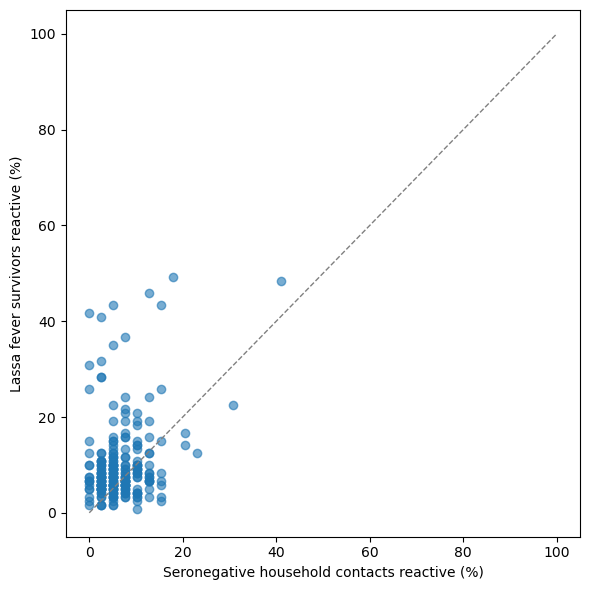

In [24]:
fig, ax = plt.subplots(figsize=(6,6))

ax.scatter(
    exposure_results['seroneg_contact_prevalence'] * 100,
    exposure_results['survivor_prevalence'] * 100,
    alpha=0.6
)

ax.plot([0, 100], [0, 100], '--', color='grey', lw=1)

ax.set_xlabel('Seronegative household contacts reactive (%)')
ax.set_ylabel('Lassa fever survivors reactive (%)')

plt.tight_layout()
plt.show()

In [25]:
NP_cluster = sig_hits.loc[
    sig_hits['sequence'].str.contains(
        'KSLQSAGF|RSLQSAGF',
        regex=True
    ),
    'peptide'
].tolist()

GPC_cluster_1 = sig_hits.loc[
    sig_hits['sequence'].str.contains(
        'CNEKHDEEFCDM'
    ),
    'peptide'
].tolist()

GPC_cluster_2 = sig_hits.loc[
    sig_hits['sequence'].str.contains(
        'DQLIMKNHLRDIMGIPYCNYSKYW'
    ),
    'peptide'
].tolist()

print(len(NP_cluster))
print(len(GPC_cluster_1))
print(len(GPC_cluster_2))

7
2
4


In [26]:
clusters = pd.DataFrame(index=df_wide_lassa.index)

clusters['NP_cluster'] = df_wide_lassa[NP_cluster].any(axis=1)
clusters['GPC_cluster_1'] = df_wide_lassa[GPC_cluster_1].any(axis=1)
clusters['GPC_cluster_2'] = df_wide_lassa[GPC_cluster_2].any(axis=1)

clusters['n_clusters'] = clusters.sum(axis=1)

In [27]:
meta = sample_meta_baseline.set_index('sample_id')

clusters = clusters.join(
    meta[
        ['Category', 'NP_FINAL_RESULT', 'GP_FINAL_RESULT']
    ]
)

In [28]:
clusters['ELISA_pattern'] = (
    clusters['NP_FINAL_RESULT'].astype(str)
    + ' / ' + 
    clusters['GP_FINAL_RESULT'].astype(str)
)

In [29]:
clusters

,NP_cluster,GPC_cluster_1,GPC_cluster_2,n_clusters,Category,NP_FINAL_RESULT,GP_FINAL_RESULT,ELISA_pattern
individual,,,,,,,,
C-109-1_5_B3,False,False,False,0,C,Negative,Negative,Negative / Negative
C-109-2_5_B5,False,False,False,0,C,Negative,Negative,Negative / Negative
C-109-3_4_E7,True,True,True,3,C,Positive,Positive,Positive / Positive
C-110-1_2_A5,False,False,False,0,C,Positive,Negative,Positive / Negative
C-110-2_3_F8,True,True,True,3,C,Positive,Positive,Positive / Positive
...,...,...,...,...,...,...,...,...
S-510_SA3_D5,True,True,True,3,S,Positive,Positive,Positive / Positive
S-511_SA5_A6,False,False,False,0,S,Negative,Positive,Negative / Positive
S-512_SA3_G9,True,True,False,2,S,Positive,Positive,Positive / Positive


In [30]:
clean = clusters[
    (clusters['Category'] == 'S') |
    (
        (clusters['Category'] == 'C') &
        (clusters['NP_FINAL_RESULT'] == 'Negative') &
        (clusters['GP_FINAL_RESULT'] == 'Negative')
    )
].copy()

clean['survivor'] = clean['Category'] == 'S'

clean['survivor'].value_counts()

survivor
True     120
False     39
Name: count, dtype: int64

In [31]:
cluster_cols = [
    'NP_cluster',
    'GPC_cluster_1',
    'GPC_cluster_2'
]

clean.groupby('survivor')[cluster_cols].mean() * 100

,NP_cluster,GPC_cluster_1,GPC_cluster_2
survivor,,,
False,41.025641,7.692308,5.128205
True,65.000000,46.666667,40.833333


In [32]:
pd.crosstab(
    clean['survivor'], 
    clean['n_clusters'], 
    normalize='index'
) * 100

n_clusters,0,1,2,3
survivor,,,,
False,48.717949,48.717949,2.564103,0.000000
True,28.333333,20.000000,22.500000,29.166667


In [33]:
for n in [1, 2, 3]:

    pred = clean['n_clusters'] >= n
    truth = clean['survivor']

    sensitivity = pred[truth].mean()
    specificity = (~pred[~truth]).mean()

    print(
        f">= {n} cluster(s): "
        f"sensitivity = {sensitivity:.1%}, "
        f"specificity = {specificity:.1%}"
    )

>= 1 cluster(s): sensitivity = 71.7%, specificity = 48.7%
>= 2 cluster(s): sensitivity = 51.7%, specificity = 97.4%
>= 3 cluster(s): sensitivity = 29.2%, specificity = 100.0%


In [34]:
from scipy.stats import fisher_exact

# ≥2 clusters
surv_pos = ((clean['survivor']) & (clean['n_clusters'] >= 2)).sum()
surv_neg = ((clean['survivor']) & (clean['n_clusters'] < 2)).sum()

ctrl_pos = ((~clean['survivor']) & (clean['n_clusters'] >= 2)).sum()
ctrl_neg = ((~clean['survivor']) & (clean['n_clusters'] < 2)).sum()

OR, p = fisher_exact([
    [surv_pos, surv_neg],
    [ctrl_pos, ctrl_neg]
])

print(surv_pos, surv_neg, ctrl_pos, ctrl_neg)
print("OR =", OR)
print("P =", p)

62 58 1 38
OR = 40.62068965517241
P = 2.9537144077893e-09


In [35]:
from statsmodels.stats.contingency_tables import Table2x2
import numpy as np

table = np.array([
    [62, 58],
    [1, 38]
])

result = Table2x2(table)

print("OR:", result.oddsratio)
print("95% CI:", result.oddsratio_confint())

OR: 40.62068965517241
95% CI: (np.float64(5.401462855871037), np.float64(305.4802878572691))


In [36]:
contacts = clusters[
    clusters['Category'] == 'C'
].copy()

In [37]:
contacts_valid = contacts[
    contacts['NP_FINAL_RESULT'].isin(['Positive', 'Negative'])
].copy()

contacts_valid['multi_epitope'] = (
    contacts_valid['n_clusters'] >= 2
)

pd.crosstab(
    contacts_valid['NP_FINAL_RESULT'],
    contacts_valid['multi_epitope']
)

multi_epitope,False,True
NP_FINAL_RESULT,,
Negative,81,1
Positive,130,64


In [38]:
table = np.array([
    [64, 130],   # NP+
    [1, 81]      # NP-
])

OR, p = fisher_exact(table)

ci = Table2x2(table).oddsratio_confint()

print(OR, ci, p)

39.87692307692308 (np.float64(5.425938501064227), np.float64(293.06800911417446)) 1.856355997762782e-10


In [87]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.contingency_tables import Table2x2
from fig_style import apply_style


protein_colors = {
    "nucleoprotein": "#4477AA",
    "glycoprotein": "#CC6677",
    "polymerase": "#999999",
    "z protein": "#AA4499",
}

def clean_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax


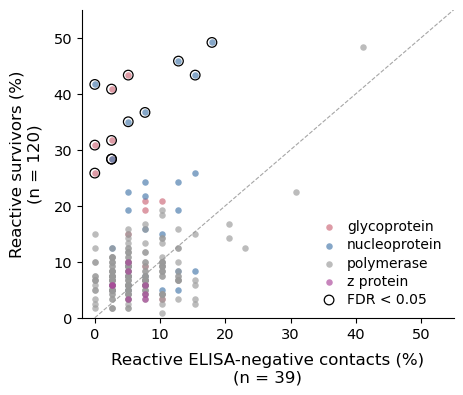

In [88]:
fig, ax = plt.subplots(figsize=(4.8, 4.))

for protein, sub in exposure_results.groupby("protein_std"):
    ax.scatter(
        100 * sub["seroneg_contact_prevalence"],
        100 * sub["survivor_prevalence"],
        s=22, alpha=0.65,
        color=protein_colors.get(protein, "#BBBBBB"),
        label=protein,
        linewidth=0,
    )

sig = exposure_results[exposure_results["FDR"] < 0.05]
ax.scatter(
    100 * sig["seroneg_contact_prevalence"],
    100 * sig["survivor_prevalence"],
    s=48, facecolors="none", edgecolors="black", linewidth=0.9,
    label="FDR < 0.05",
)

ax.plot([0, 70], [0, 70], ls="--", lw=0.8, color="0.65", zorder=0)

clean_axes(ax)

# Increase text size
ax.set_xlabel(
    "Reactive ELISA-negative contacts (%)\n(n = 39)",
    fontsize=12,
    labelpad=8
)

ax.set_ylabel(
    "Reactive survivors (%)\n(n = 120)",
    fontsize=12,
    labelpad=8
)

ax.tick_params(
    axis="both",
    labelsize=10.5
)

ax.legend(
    frameon=False,
    loc="lower right",
    handletextpad=0.3,
    fontsize=10,
    borderaxespad=0.4,
    labelspacing=0.3,
)

ax.set_ylim(0, 55)
ax.set_xlim(-2, 55)

#fig.tight_layout()
fig.savefig("./output_figures/LASV_exposure_panel_peptide_discrimination.svg", bbox_inches="tight")
plt.show()


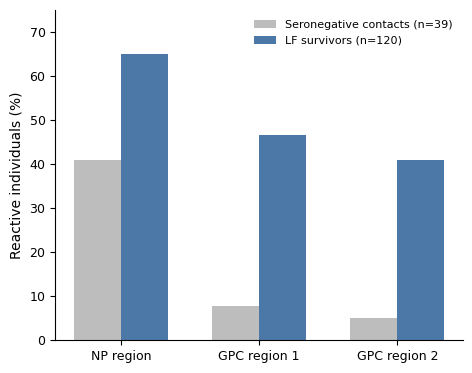

In [41]:
cluster_labels = {
    "NP_cluster": "NP region",
    "GPC_cluster_1": "GPC region 1",
    "GPC_cluster_2": "GPC region 2",
}

plot_cluster = (
    clean.groupby("survivor")[list(cluster_labels)]
    .mean().mul(100).T
    .rename(columns={False: "Seronegative contacts", True: "LF survivors"})
)

x = np.arange(len(plot_cluster))
width = 0.34
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.bar(x - width/2, plot_cluster["Seronegative contacts"], width,
       label="Seronegative contacts (n=39)", color="#BDBDBD")
ax.bar(x + width/2, plot_cluster["LF survivors"], width,
       label="LF survivors (n=120)", color="#4C78A8")
ax.set_xticks(x, [cluster_labels[c] for c in plot_cluster.index])
ax.set_ylabel("Reactive individuals (%)")
ax.set_ylim(0, 75)
clean_axes(ax)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("./output_figures/LASV_exposure_panel_C_cluster_prevalence.svg", bbox_inches="tight")
plt.show()


In [42]:
breadth = pd.crosstab(clean["survivor"], clean["n_clusters"], normalize="index").mul(100)
breadth = breadth.reindex(index=[False, True], columns=[0,1,2,3], fill_value=0)

fig, ax = plt.subplots(figsize=(4.4, 3.9))
bottom = np.zeros(2)
stack_colors = ["#E0E0E0", "#BDBDBD", "#72A0C1", "#2F5D8A"]
for n, color in zip([0,1,2,3], stack_colors):
    vals = breadth[n].values
    ax.bar([0,1], vals, bottom=bottom, width=0.65, label=f"{n} region{'s' if n != 1 else ''}", color=color)
    bottom += vals

ax.set_xticks([0,1], ["Seronegative contacts
(n=39)", "LF survivors
(n=120)"])
ax.set_ylabel("Individuals (%)")
ax.set_ylim(0,100)
clean_axes(ax)
ax.legend(frameon=False, title="Regions recognized", bbox_to_anchor=(1.02,1), loc="upper left")
ax.text(0.5, 103, "≥2 regions: 2.6% vs 51.7%
OR 40.6, Fisher P = 2.95×10⁻⁹",
        ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig("./output_figures/LASV_exposure_panel_D_breadth.svg", bbox_inches="tight")
plt.show()


SyntaxError: unterminated string literal (detected at line 12) (4241694494.py, line 12)

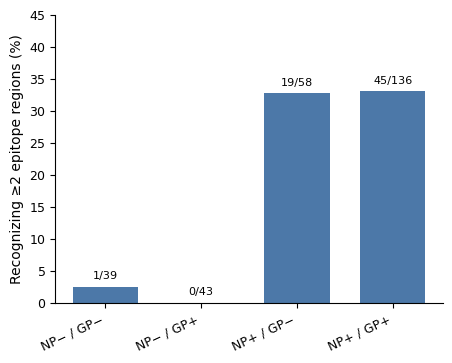

,sum,count,mean,percent
ELISA_pattern,,,,
NP− / GP−,1,39,0.025641,2.564103
NP− / GP+,0,43,0.000000,0.000000
NP+ / GP−,19,58,0.327586,32.758621
NP+ / GP+,45,136,0.330882,33.088235


In [ ]:
contacts_plot = clusters[clusters["Category"].eq("C")].copy()
contacts_plot = contacts_plot[contacts_plot["NP_FINAL_RESULT"].isin(["Positive","Negative"]) & contacts_plot["GP_FINAL_RESULT"].isin(["Positive","Negative"])]
contacts_plot["ELISA_pattern"] = contacts_plot["NP_FINAL_RESULT"].str[0] + "P / " + contacts_plot["GP_FINAL_RESULT"].str[0] + "P"
# Replace compact labels explicitly
contacts_plot["ELISA_pattern"] = contacts_plot["ELISA_pattern"].replace({"NP / NP":"NP− / GP−"})
pattern_map = {
    ("Negative","Negative"): "NP− / GP−",
    ("Negative","Positive"): "NP− / GP+",
    ("Positive","Negative"): "NP+ / GP−",
    ("Positive","Positive"): "NP+ / GP+",
}
contacts_plot["ELISA_pattern"] = [pattern_map[(a,b)] for a,b in zip(contacts_plot["NP_FINAL_RESULT"], contacts_plot["GP_FINAL_RESULT"])]
contacts_plot["multi_epitope"] = contacts_plot["n_clusters"] >= 2
order = ["NP− / GP−", "NP− / GP+", "NP+ / GP−", "NP+ / GP+"]
contact_summary = contacts_plot.groupby("ELISA_pattern")["multi_epitope"].agg(["sum","count","mean"]).reindex(order)
contact_summary["percent"] = 100 * contact_summary["mean"]

fig, ax = plt.subplots(figsize=(4.6, 3.7))
ax.bar(np.arange(4), contact_summary["percent"], color="#4C78A8", width=0.68)
ax.set_xticks(np.arange(4), order, rotation=25, ha="right")
ax.set_ylabel("Recognizing ≥2 epitope regions (%)")
ax.set_ylim(0, 45)
clean_axes(ax)
for i, row in enumerate(contact_summary.itertuples()):
    ax.text(i, row.percent + 1.2, f"{int(row.sum)}/{int(row.count)}", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig("./output_figures/LASV_exposure_panel_E_contacts_ELISA.svg", bbox_inches="tight")
plt.show()
contact_summary
